## Mini Project: Dry Bean Type Classification

An agriculture company approaches you with a challenge: they are currently classifying different types of dry beans manually, a process that is labour-intensive, prone to errors and inefficient at scale. They want to automate this classification process using Artificial Intelligence to improve accuracy, reduce operational costs and ensure consistent quality in packaging and distribution.

As a data scientist, your role is to help them build a machine learning solution that can accurately classify bean types based on physical characteristics such as area, perimeter, shape and compactness. By doing this, you'll:
-	Automate the bean classification process using supervised learning techniques
-	Help the company reduce manual labour and cost
-	Improve the speed and reliability of quality control operations
-	Deliver a scalable solution for real-time classification in industrial settings
This project not only enhances your understanding of supervised machine learning but also demonstrates how AI can be directly applied to Agri-tech and food processing industries for tangible business impact.

Data Dictionary
All configurations (like area, shape and roundness) of data were gathered through camera-based systems using computer vision algorithms—a method commonly used in modern agricultural quality control setups.
Attribute Information:
1.	Area (A): The area of a bean zone and the number of pixels within its boundaries.
2.	Perimeter (P): Bean circumference is defined as the length of its border.
3.	Major axis length (L): The distance between the ends of the longest line that can be drawn from a bean.
4.	Minor axis length (l): The longest line that can be drawn from the bean while standing perpendicular to the main axis.
5.	Aspect ratio (K): Defines the relationship between L and l.
6.	Eccentricity (Ec): Eccentricity of the ellipse having the same moments as the region.
7.	Convex area (C): Number of pixels in the smallest convex polygon that can contain the area of a bean seed.
8.	Equivalent diameter (Ed): The diameter of a circle having the same area as a bean seed area.
9.	Extent (Ex): The ratio of the pixels in the bounding box to the bean area.
10.	Solidity (S): Also known as convexity. The ratio of the pixels in the convex shell to those found in beans.
11.	Roundness (R): Calculated with the following formula: (4piA)/(P^2)
12.	Compactness (CO): Measures the roundness of an object: Ed/L
13.	ShapeFactor1 (SF1)
14.	ShapeFactor2 (SF2)
15.	ShapeFactor3 (SF3)
16.	ShapeFactor4 (SF4)
17.	Class (Seker, Barbunya, Bombay, Cali, Dermosan, Horoz and Sira) 

1. Import and Load the Data
-	Import necessary libraries (pandas, numpy, matplotlib, seaborn, sklearn etc.)

In [13]:
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import  accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

-	Load the dataset and explore it using .head(), .info(), and .describe()

In [2]:
DF_DB = pd.read_excel('Dry_Bean_Dataset.xlsx')
display(DF_DB.head())
display(DF_DB.info())
display(DF_DB.describe())

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

None

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


2. Exploratory Data Analysis (EDA)
-	Visualize distributions of features using histograms and boxplots
-	Analyze the class distribution (check for class imbalance)
-	Plot feature correlations (eg heatmap)
-	Visualize multivariate relationships (pairplot)
-	Summarize key findings

### Data Distribution of Each Feature (Boxplot)

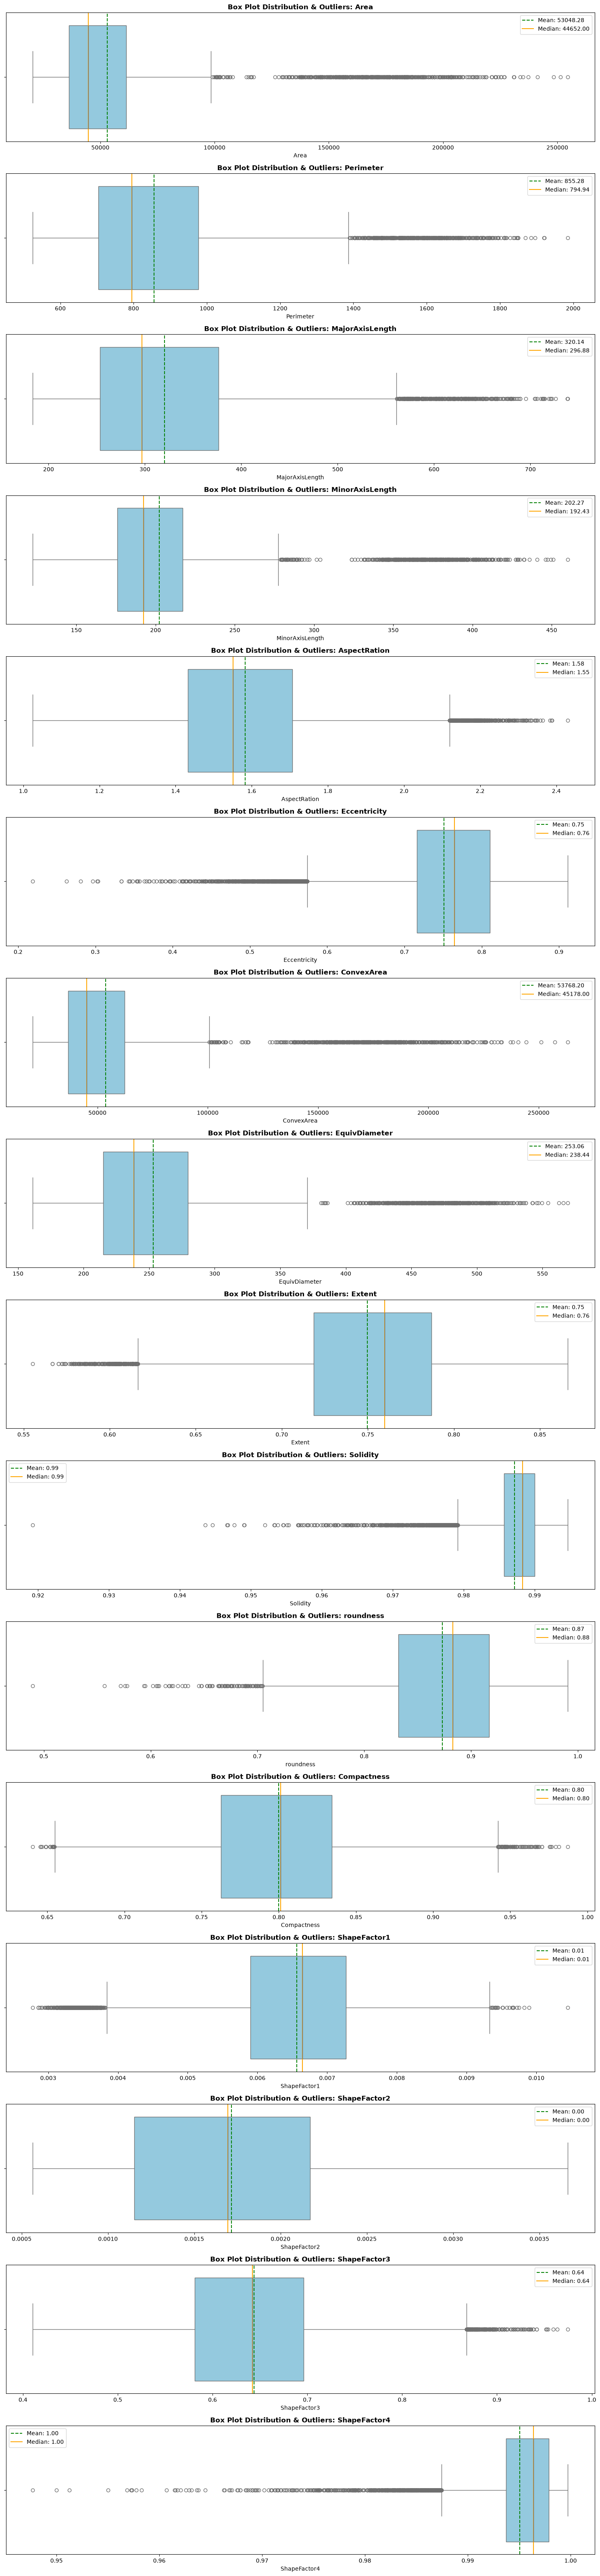

In [3]:
num_cols = DF_DB.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(15, 4 * len(num_cols)))

for i, col in enumerate(num_cols, 1):
    plt.subplot(len(num_cols), 1, i)
    
    sns.boxplot(x=DF_DB[col], color='skyblue')
    
    mean_val = DF_DB[col].mean()
    median_val = DF_DB[col].median()
    plt.axvline(mean_val, color='green', linestyle='--', label=f'Mean: {mean_val:.2f}')
    plt.axvline(median_val, color='orange', linestyle='-', label=f'Median: {median_val:.2f}')
    
    plt.title(f'Box Plot Distribution & Outliers: {col}', fontsize=12, fontweight='bold')
    plt.legend()

plt.tight_layout()
plt.show()

1. Area (Top): Heavily right-skewed with a compact interquartile range (IQR) near the lower end and a long tail of extreme high-value outliers.

2. Perimeter: Right-skewed distribution featuring a moderate IQR and a dense trail of extended outliers on the upper side.

3. Major Axis Length: Right-skewed with a wider central spread and a prominent upper tail of outliers.

4. Minor Axis Length: Right-skewed with a narrow box shifted towards lower values and a stretched upper whisker with outliers.

5. Aspect Ratio: Moderately right-skewed, with its box in the lower-middle range and a concentrated cluster of high-value outliers.

6. Eccentricity: Left-skewed, where the box is positioned toward the higher end with a long tail of lower-value outliers extending to the left.

7. Convex Area: Strongly right-skewed, showing a tight IQR near the lower end and an extensive trail of high-end outliers.

8. Equivalent Diameter: Right-skewed with a compact box on the lower-left and a significant spread of upper outliers.

9. Extent: Slightly left-skewed, featuring a wide box positioned toward the right and minor low-value outliers.

10. Solidity:Strongly left-skewed, with a very narrow IQR pressed tightly against the maximum value and a long trail of low-value outliers.

11. Roundness: Left-skewed, with the box situated on the right side and a trail of outliers stretching past the left whisker.

12. Compactness: Approximately symmetric, with the mean and median closely overlapping at the center and minor outliers on both extremes.

13. Shape Factor 1: Nearly symmetric, showing a balanced box and whiskers with minimal outliers on both ends.

14. Shape Factor 2: Symmetric and uniformly spread, featuring a wide box, balanced whiskers, overlapping central tendencies, and **no visible outliers**.

15. Shape Factor 3: Slightly right-skewed, with the box in the lower-middle region and a small detached cluster of outliers on the far right.

16. Shape Factor 4: Extremely left-skewed, with a tight IQR pressed against the far right edge and an extensive trail of low-value outliers.

### Skewness of Data Features (Histogram)

Area               2.952931
ConvexArea         2.941821
MinorAxisLength    2.238211
EquivDiameter      1.948958
Perimeter          1.626124
MajorAxisLength    1.357815
AspectRation       0.582573
ShapeFactor2       0.301226
ShapeFactor3       0.242481
Compactness        0.037115
ShapeFactor1      -0.534141
roundness         -0.635749
Extent            -0.895348
Eccentricity      -1.062824
Solidity          -2.550093
ShapeFactor4      -2.759483
dtype: float64

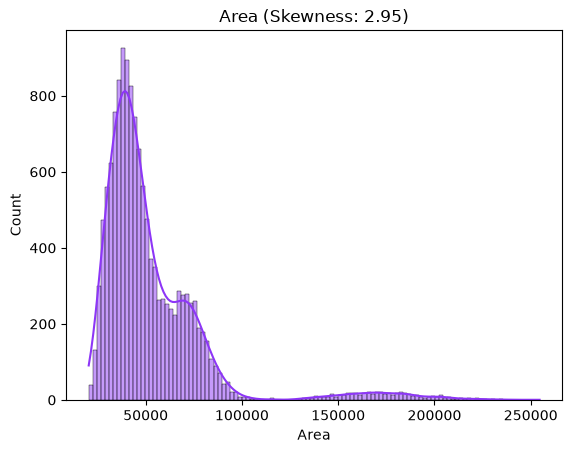

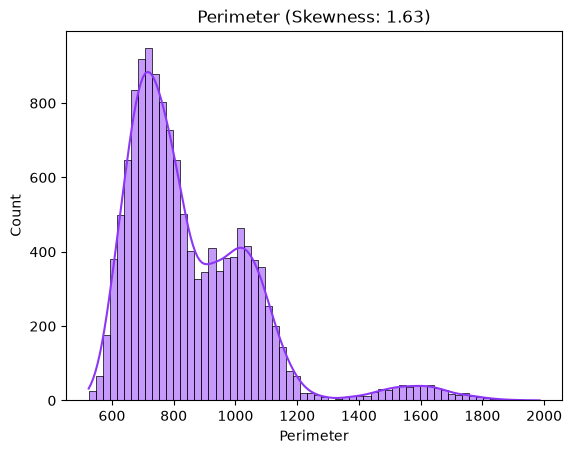

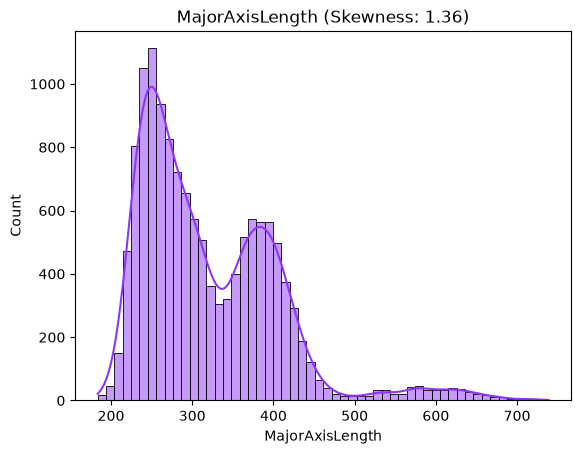

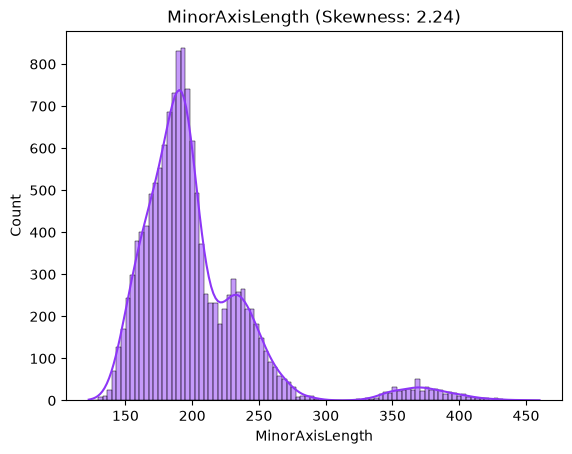

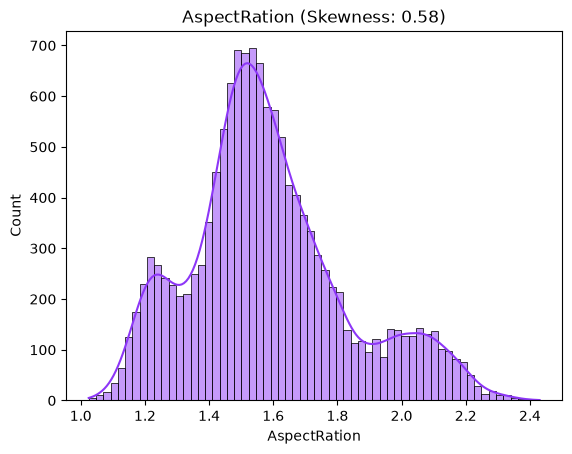

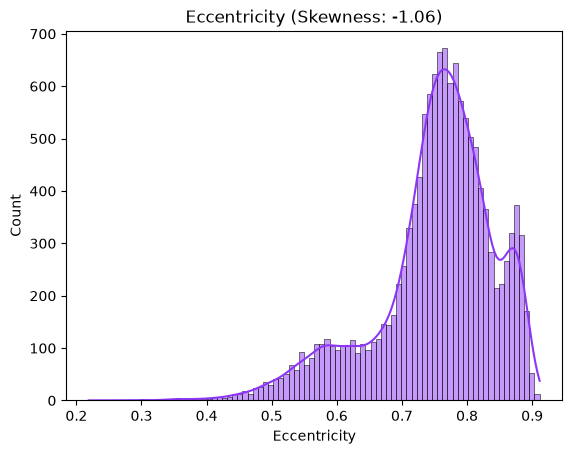

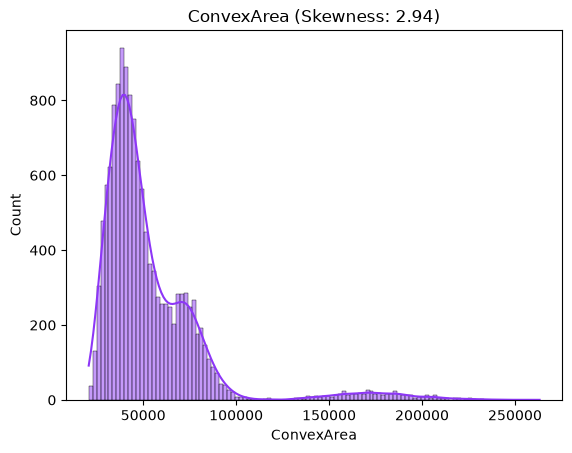

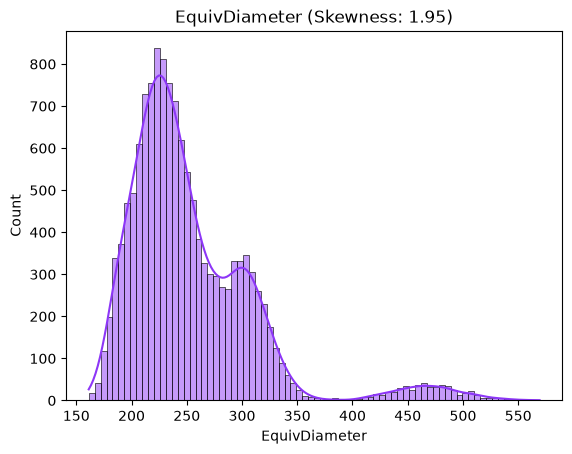

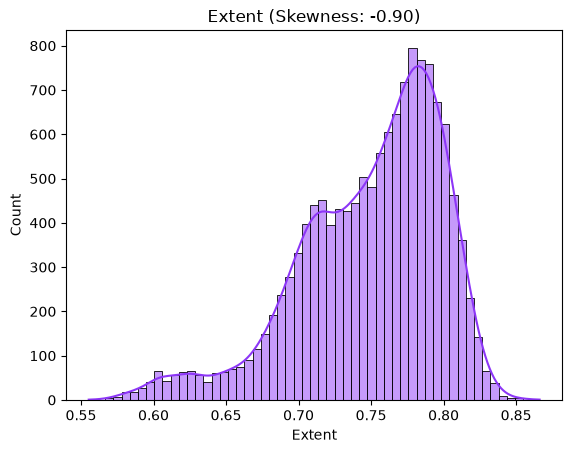

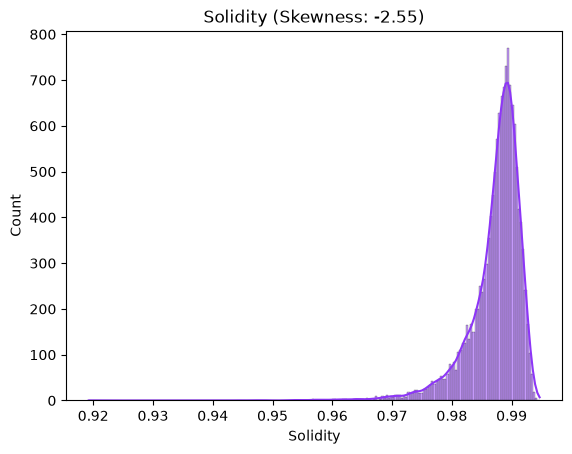

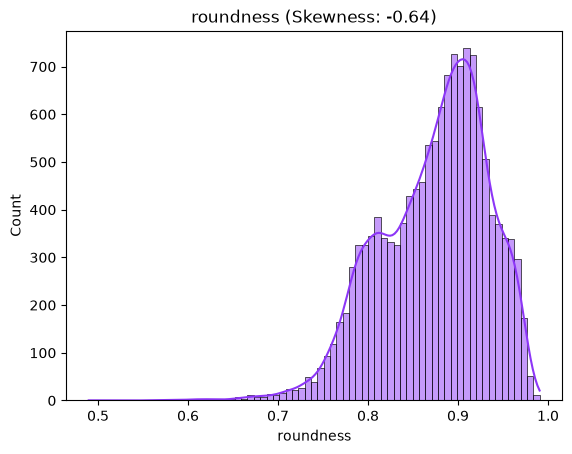

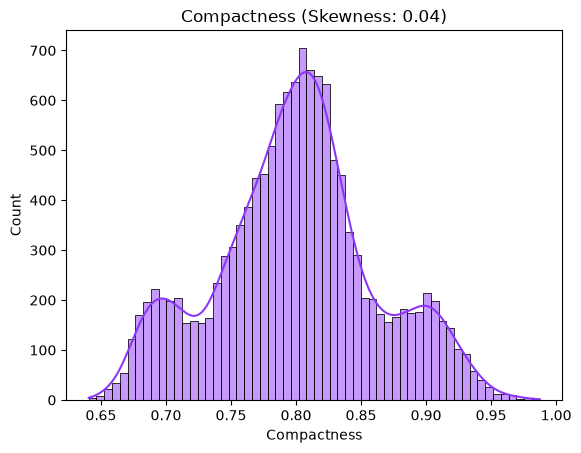

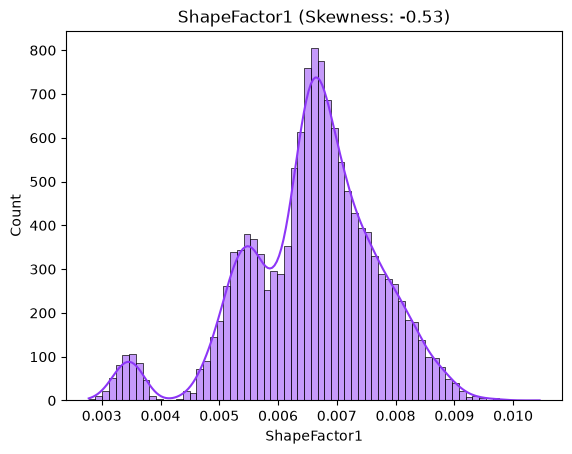

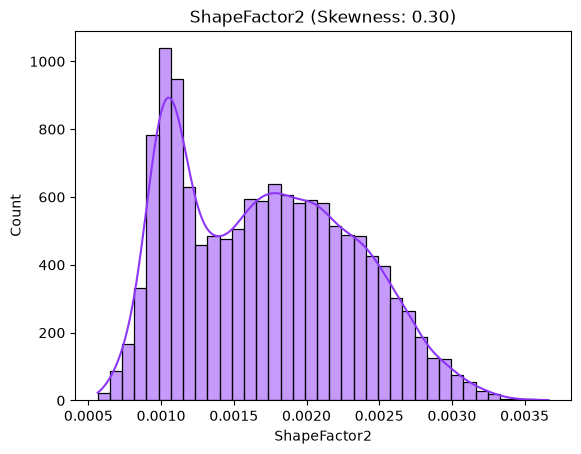

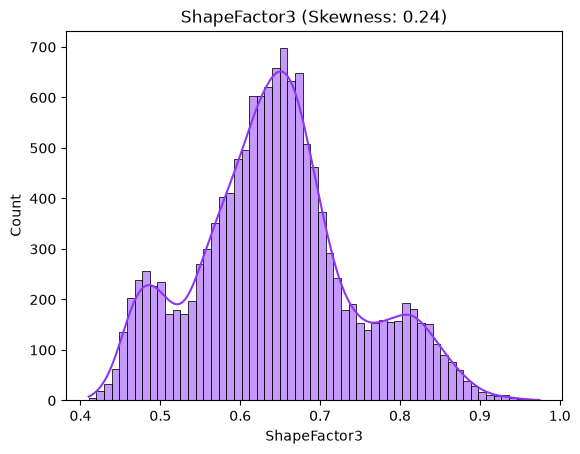

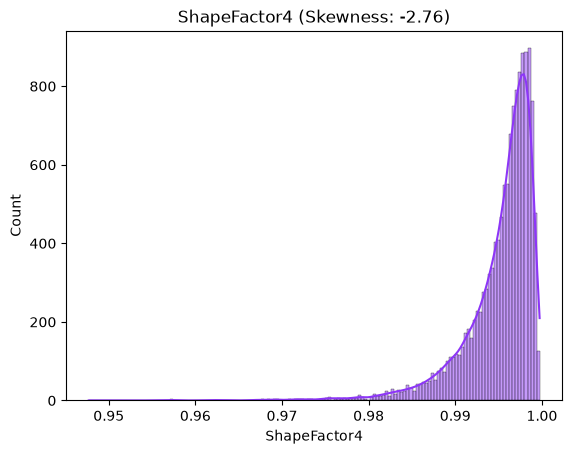

In [4]:
DF_DB_NUM = DF_DB.select_dtypes(include=[np.number])

skewness = DF_DB_NUM.skew().sort_values(ascending=False)
display(DF_DB_NUM.skew().sort_values(ascending=False))

cols = DF_DB_NUM.skew().index

for col in cols:
    sns.histplot(data=DF_DB_NUM, x=col, kde=True, color="#8D36F7")
    plt.title(f'{col} (Skewness: {skewness[col]:.2f})')
    plt.show()

Area:

* Distribution Shape: The feature exhibits a strong right-skewness with a skewness coefficient of 2.95.
* Central Tendency & Frequency: The highest density (count exceeding 800) is heavily concentrated between approximately 30,000 and 50,000.
* Secondary Bump: There is a smaller secondary peak or bump visible around 65,000 to 75,000 before the distribution tails off.
* Long Tail / Outliers: A sparse, extended tail stretches far to the right up to around 250,000, which corresponds to the outliers observed previously in the box plot.

Perimeter:

* Distribution Shape: The feature exhibits a right-skewness coefficient of 1.63.
* Primary Concentration: The highest frequency of data points is concentrated between roughly 650 and 800, with a peak count exceeding 900.
* Secondary Mode: A distinct secondary bump is visible in the distribution around 1,000 to 1,100.
* Right Tail: A sparse, extended tail stretches toward the higher values, reaching up to approximately 2,000.

MajorAxisLength:

* Distribution Shape: The MajorAxisLength feature exhibits a moderate positive (right) skewness with a skewness value of 1.36.
* Primary Concentration: The highest frequency of observations is tightly clustered between 220 and 280, reaching a peak count of over 1,100 around 250.
* Secondary Mode: A prominent secondary peak is present between 360 and 420 (peaking near 390 with counts close to 575), indicating a clear bimodal pattern that likely distinguishes specific sub-categories within your 6 classes.
* Right Tail: Beyond 460, the distribution tapers off into a sparse tail extending up to roughly 740, with a minor cluster of high-value outliers around 550 to 650.

MinorAxisLength:

* Distribution Shape: The MinorAxisLength feature exhibits a strong positive (right) skewness with a skewness coefficient of 2.24.
* Primary Concentration: The highest frequency of observations is tightly clustered between 160 and 210, peaking just above 830 around 190–195.
* Secondary Mode: A distinct secondary bump appears around 225 to 245 (peaking just under 300), suggesting a subgroup separation among your categories.
* Detached Outlier Cluster: After tapering near zero around 300, a noticeable detached cluster of high-value observations emerges between 340 and 420 (peaking around 370), extending up to roughly 460.

AspectRation:

* Distribution Shape: The AspectRation feature shows a mild positive (right) skewness with a coefficient of 0.58.
* Multi-Modal Structure: The distribution displays three distinct peaks (trimodal pattern) rather than a single bell curve, which strongly indicates natural separation among your categories:
* Primary Peak: The largest concentration sits between 1.45 and 1.65, reaching a peak count near 700 around 1.50–1.55.
* Lower Secondary Peak: A prominent shoulder appears on the left around 1.20 to 1.28, peaking close to 280.
* Upper Secondary Peak: A broader, flatter bump appears on the right between 1.95 and 2.15, with counts hovering around 130–140.
* Overall Spread: Values span smoothly from roughly 1.02 up to 2.43 without extreme, detached outliers.

Eccentricity:

* Distribution Shape: The Eccentricity feature exhibits a moderate negative (left) skewness with a skewness coefficient of -1.06.
* Primary Concentration: The highest frequency of data points is concentrated between 0.72 and 0.82, reaching a peak count of roughly 670 around 0.76–0.77.
* Secondary Peaks: A sharp secondary peak appears near the upper end around 0.87–0.88 (with counts reaching approximately 370), alongside a flatter shoulder on the left between 0.55 and 0.65 (hovering around counts of 100–115).
* Left Tail: The distribution tapers gradually toward the lower values, forming a long tail extending down to roughly 0.22.

ConvexArea:

* Distribution Shape: The ConvexArea feature exhibits a strong positive (right) skewness with a skewness coefficient of 2.94.
* Primary Concentration: The highest density of observations is clustered between approximately 30,000 and 50,000, peaking above 900 around 38,000–40,000.
* Secondary Bump: A smaller secondary bump appears between 65,000 and 80,000 (peaking just under 300) before tapering down toward 105,000.
* Detached Right Tail: A sparse, extended tail stretches from around 130,000 up to roughly 260,000 (peaking slightly around 170,000), closely mirroring the distribution of Area and indicating strong multicollinearity between the two features.

EquivDiameter:

* Distribution Shape: The EquivDiameter feature exhibits a strong positive (right) skewness with a skewness coefficient of 1.95.
* Primary Concentration: The highest frequency of observations is tightly clustered between 200 and 250, peaking at over 830 around 225.
* Secondary Mode: A clear secondary bump appears between 290 and 315 (peaking just under 350), reflecting sub-category separation within the dataset.
* Detached Right Tail: After tapering down near zero around 375, a small, detached cluster of high-value observations emerges between 410 and 530 (peaking slightly around 465–475), extending up to roughly 570.

Extent:

* Distribution Shape: The Extent feature exhibits a moderate negative (left) skewness with a skewness coefficient of -0.90.
* Primary Concentration: The highest density of observations is concentrated toward the upper end between 0.76 and 0.80, reaching a peak count of nearly 800 around 0.78.
* Secondary Shoulder: A distinct secondary bump or shoulder appears in the middle range between 0.70 and 0.73, peaking around 450.
* Left Tail: The distribution tapers down toward the lower values, forming a gradual tail extending from roughly 0.66 down to 0.56 with low counts (under 70).

Solidity:

* Distribution Shape: The Solidity feature exhibits a strong negative (left) skewness with a skewness coefficient of -2.55.
* Primary Concentration: The vast majority of observations are tightly concentrated near the upper boundary between 0.985 and 0.993, peaking sharply above 750 around 0.989–0.990.
* Unimodal Peak: Unlike several previous features, Solidity shows a single, sharp peak rather than distinct secondary bumps.
* Left Tail: Below 0.980, counts drop rapidly into a very thin, extended left tail reaching all the way down to roughly 0.92, representing sparse low-value outliers.

Roundness:

* Distribution Shape: The roundness feature exhibits a moderate negative (left) skewness with a skewness coefficient of -0.64.
* Primary Concentration: The highest density of observations is concentrated between 0.87 and 0.93, reaching a peak count of roughly 740 around 0.90–0.91.
* Secondary Shoulder: A distinct secondary bump appears on the left slope between 0.78 and 0.83, peaking just below 400 around 0.81.
* Left Tail: Below 0.75, frequencies drop steadily into a thin left tail extending down to roughly 0.49.

Compactness:

* Distribution Shape: The Compactness feature is nearly symmetric with a skewness coefficient of 0.04.
* Trimodal Structure: While balanced overall, the distribution exhibits three distinct peaks rather than a single normal curve, reflecting clear separation among your categories:
* Central Primary Peak: The highest concentration sits between 0.78 and 0.83, peaking at approximately 700 around 0.80–0.81.
* Left Secondary Peak: A smaller, distinct bump appears around 0.69 to 0.71, reaching a count of roughly 220.
* Right Secondary Peak: A symmetrical counterpart bump appears around 0.89 to 0.91, peaking just above 210.
* Overall Spread: Values span evenly from roughly 0.64 to 0.99 without extreme, detached outliers.

ShapeFactor1:

* Distribution Shape: The ShapeFactor1 feature exhibits a mild negative (left) skewness with a skewness coefficient of -0.53.
* Trimodal Structure: The distribution displays three distinct peaks, reflecting clear separation among different categories in the dataset:
* Primary Peak: The largest concentration lies between 0.0063 and 0.0070, reaching a peak count just above 800 around 0.0066–0.0067.
* Middle Secondary Peak: A prominent shoulder appears between 0.0052 and 0.0058, peaking near 380 around 0.0055.
* Detached Left Cluster: A separate, smaller peak emerges at the lower end between 0.0030 and 0.0039 (peaking just over 100 around 0.0035), isolated from the main body by a gap near 0.0041.
* Overall Spread: Values range from roughly 0.0028 up to 0.0105, tapering smoothly on the right side beyond 0.0090.

ShapeFactor2:

* Distribution Shape: The ShapeFactor2 feature exhibits a mild positive (right) skewness with a skewness coefficient of 0.30.
* Bimodal Structure: The distribution displays two distinct peaks, highlighting strong separation among different categories in your dataset:
* Primary Peak: A sharp, narrow peak is concentrated at the lower end between 0.0009 and 0.0012, reaching a count of over 1,000 around 0.0010–0.0011.
* Broad Secondary Peak: A much wider, flatter mound spans from roughly 0.0015 to 0.0024, peaking around 635 near 0.0017–0.0018.
* Overall Spread: Values range smoothly from roughly 0.00055 up to 0.00365, tapering gradually on the right without detached outliers.

ShapeFactor3:

* Distribution Shape: The ShapeFactor3 feature is nearly symmetric with a slight positive (right) skewness coefficient of 0.24.
* Trimodal Structure: Similar to Compactness, the distribution displays three distinct peaks, highlighting clear subgroup separation across categories:
* Central Primary Peak: The main concentration sits between 0.61 and 0.68, reaching a peak count just under 700 around 0.65.
* Left Secondary Peak: A distinct shoulder emerges on the lower end around 0.47 to 0.50, peaking near 255.
* Right Secondary Peak: A broader secondary bump appears toward the upper end between 0.78 and 0.84, peaking just below 200 around 0.81.
* Overall Spread: Values span continuously from roughly 0.41 up to 0.98 without detached outliers.

ShapeFactor4:

* Distribution Shape: The ShapeFactor4 feature exhibits a strong negative (left) skewness with a skewness coefficient of -2.76.
* Primary Concentration: The vast majority of observations are tightly packed near the upper boundary between 0.995 and 0.999, reaching a sharp peak count close to 900 around 0.998.
* Unimodal Peak: Like Solidity, this feature displays a single, sharp peak right against the upper limit rather than distinct secondary bumps.
* Left Tail: Below 0.990, counts drop steeply into a long, sparse left tail extending down to roughly 0.948, representing low-value outliers.

### Class Distribution of Data Features (Imbalance Check)

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

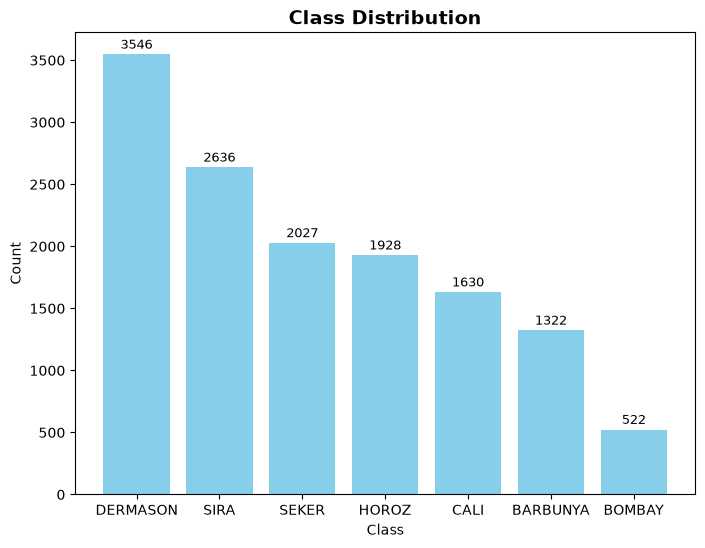

In [5]:
DF_DB['Class'] = DF_DB['Class'].astype('category')
display(DF_DB['Class'].value_counts())
plt.figure(figsize=(8, 6))
BarChart = plt.bar(DF_DB['Class'].value_counts().index.to_numpy(), DF_DB['Class'].value_counts(), color='skyblue')
plt.title('Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Count')
plt.bar_label(BarChart, labels=DF_DB['Class'].value_counts().to_numpy(), padding=2, fontsize=9)
plt.show()

7-Class Structure: The target variable actually consists of 7 distinct bean varieties (DERMASON, SIRA, SEKER, HOROZ, CALI, BARBUNYA, and BOMBAY) totaling 13,611 samples.

Significant Class Imbalance: The dataset is noticeably imbalanced, with the majority class (DERMASON at 3,546 instances) having nearly 6.8 times more samples than the smallest minority class (BOMBAY at 522 instances).

Distribution Tiering:
* High Representation: DERMASON (3,546) and SIRA (2,636) together account for over 45% of the entire dataset.
* Moderate Representation: SEKER (2,027), HOROZ (1,928), CALI (1,630), and BARBUNYA (1,322) form a steady middle tier.
* Low Representation: BOMBAY (522) is heavily underrepresented, which directly explains the small detached outlier clusters seen earlier in size features like Area, Perimeter, and MinorAxisLength.

### Correlation Check (Heatmap)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.966722,0.931834,0.951602,0.241735,0.267481,0.999939,0.984968,0.054345,-0.196585,-0.357530,-0.268067,-0.847958,-0.639291,-0.272145,-0.355721
Perimeter,0.966722,1.000000,0.977338,0.913179,0.385276,0.391066,0.967689,0.991380,-0.021160,-0.303970,-0.547647,-0.406857,-0.864623,-0.767592,-0.408435,-0.429310
MajorAxisLength,0.931834,0.977338,1.000000,0.826052,0.550335,0.541972,0.932607,0.961733,-0.078062,-0.284302,-0.596358,-0.568377,-0.773609,-0.859238,-0.568185,-0.482527
MinorAxisLength,0.951602,0.913179,0.826052,1.000000,-0.009161,0.019574,0.951339,0.948539,0.145957,-0.155831,-0.210344,-0.015066,-0.947204,-0.471347,-0.019326,-0.263749
AspectRation,0.241735,0.385276,0.550335,-0.009161,1.000000,0.924293,0.243301,0.303647,-0.370184,-0.267754,-0.766979,-0.987687,0.024593,-0.837841,-0.978592,-0.449264
Eccentricity,0.267481,0.391066,0.541972,0.019574,0.924293,1.000000,0.269255,0.318667,-0.319362,-0.297592,-0.722272,-0.970313,0.019920,-0.860141,-0.981058,-0.449354
ConvexArea,0.999939,0.967689,0.932607,0.951339,0.243301,0.269255,1.000000,0.985226,0.052564,-0.206191,-0.362083,-0.269922,-0.847950,-0.640862,-0.274024,-0.362049
EquivDiameter,0.984968,0.991380,0.961733,0.948539,0.303647,0.318667,0.985226,1.000000,0.028383,-0.231648,-0.435945,-0.327650,-0.892741,-0.713069,-0.330389,-0.392512
Extent,0.054345,-0.021160,-0.078062,0.145957,-0.370184,-0.319362,0.052564,0.028383,1.000000,0.191389,0.344411,0.354212,-0.141616,0.237956,0.347624,0.148502
Solidity,-0.196585,-0.303970,-0.284302,-0.155831,-0.267754,-0.297592,-0.206191,-0.231648,0.191389,1.000000,0.607150,0.303766,0.153388,0.343559,0.307662,0.702163


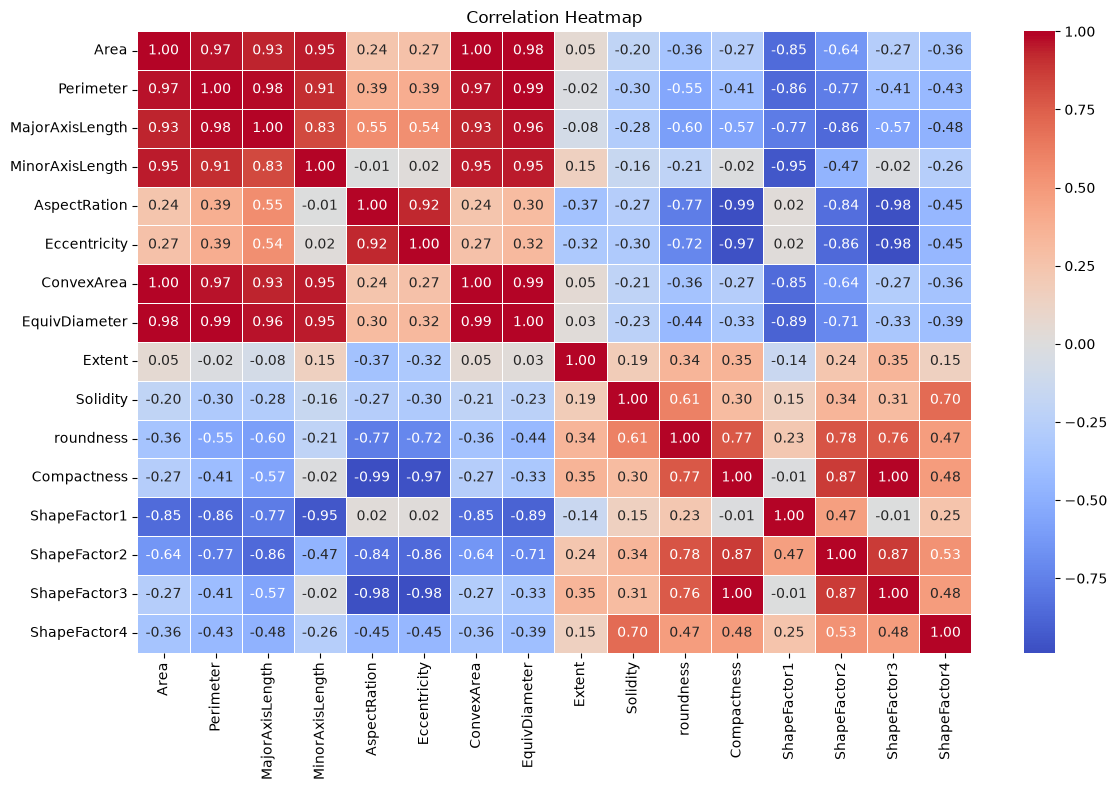

In [6]:
Corr_Matrix = DF_DB.select_dtypes(include=[np.number]).corr()

display(Corr_Matrix)

plt.figure(figsize=(12, 8))

sns.heatmap(Corr_Matrix,annot=True,cmap='coolwarm',center=0,fmt='.2f',linewidths=0.5)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

* Strong Multicollinearity Clusters: Area, Perimeter, MajorAxisLength, MinorAxisLength, ConvexArea, and EquivDiameter exhibit extremely high positive correlations with each other (values generally ranging from 0.83 to 1.00), forming a dense cluster of redundant geometric measures. Similarly, AspectRation and Eccentricity show an intense positive correlation of 0.92, while Compactness and ShapeFactor3 correlate at 1.00.

* Strong Inverse Relationships: AspectRation and Eccentricity both show near-perfect negative correlations with Compactness (-0.99 and -0.97 respectively) and ShapeFactor3 (-0.98 for both), indicating that as elongation increases, compactness and shape factor metrics drop sharply. MinorAxisLength also displays a strong negative correlation of -0.95 with ShapeFactor1.

* Independent or Low-Correlation Features: Extent stands out with generally weak correlation coefficients across most other variables (mostly hovering between -0.37 and 0.35), suggesting it captures distinct variance that is not redundantly explained by the primary size and shape measures.

### Visualize multivariate relationships (pairplot)

In [ ]:
sns.pairplot(DF_DB, hue='Class', palette='Set2', diag_kind='kde')
plt.show()

3. Missing Values & Outlier Treatment
-	Check for and handle missing values
-	Detect and treat outliers if needed (Z-score / IQR methods/boxplots)

### Missing Values and Outliers

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Series([], dtype: float64)

'Outliers for Column Area'

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
3344,100846,1297.770,469.285655,274.423910,1.710076,0.811200,102015,358.331013,0.792036,0.988541,0.752442,0.763567,0.004653,0.000976,0.583034,0.997033,BARBUNYA
3345,102015,1271.970,456.791895,286.894421,1.592195,0.778162,103901,360.401904,0.804973,0.981848,0.792356,0.788985,0.004478,0.001070,0.622497,0.991137,BARBUNYA
3346,102379,1296.377,456.722068,286.557574,1.593823,0.778679,104111,361.044307,0.739412,0.983364,0.765523,0.790512,0.004461,0.001075,0.624909,0.995995,BARBUNYA
3347,105542,1265.623,466.135980,288.999342,1.612931,0.784610,107112,366.579116,0.747888,0.985342,0.827993,0.786421,0.004417,0.001042,0.618458,0.997530,BARBUNYA
3348,115967,1359.763,449.454969,331.305270,1.356619,0.675755,118497,384.257427,0.742712,0.978649,0.788166,0.854941,0.003876,0.001277,0.730924,0.991585,BARBUNYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5496,106806,1263.899,494.727002,276.176469,1.791344,0.829679,108109,368.767708,0.705451,0.987947,0.840196,0.745396,0.004632,0.000882,0.555616,0.995299,CALI
5497,107911,1298.822,498.597779,279.350337,1.784848,0.828309,110337,370.670410,0.731898,0.978013,0.803852,0.743426,0.004620,0.000871,0.552682,0.986453,CALI
5498,114858,1300.819,512.736642,287.561719,1.783049,0.827926,115826,382.415674,0.688713,0.991643,0.852977,0.745833,0.004464,0.000852,0.556266,0.991850,CALI
5499,115608,1298.623,500.298310,296.898826,1.685080,0.804876,117222,383.662192,0.779650,0.986231,0.861453,0.766867,0.004328,0.000923,0.588085,0.990970,CALI


'Extreme Outliers for Column Area'

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
3347,105542,1265.623,466.135980,288.999342,1.612931,0.784610,107112,366.579116,0.747888,0.985342,0.827993,0.786421,0.004417,0.001042,0.618458,0.997530,BARBUNYA
3348,115967,1359.763,449.454969,331.305270,1.356619,0.675755,118497,384.257427,0.742712,0.978649,0.788166,0.854941,0.003876,0.001277,0.730924,0.991585,BARBUNYA
3349,114004,1279.356,451.361256,323.747996,1.394175,0.696795,115298,380.991340,0.748987,0.988777,0.875280,0.844094,0.003959,0.001240,0.712495,0.993342,BOMBAY
3350,117034,1265.926,425.923787,351.215109,1.212715,0.565722,118019,386.021135,0.746319,0.991654,0.917710,0.906315,0.003639,0.001515,0.821407,0.996132,BOMBAY
3351,126503,1326.959,475.772459,339.381887,1.401879,0.700830,128220,401.333555,0.771313,0.986609,0.902809,0.843541,0.003761,0.001175,0.711561,0.997523,BOMBAY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5496,106806,1263.899,494.727002,276.176469,1.791344,0.829679,108109,368.767708,0.705451,0.987947,0.840196,0.745396,0.004632,0.000882,0.555616,0.995299,CALI
5497,107911,1298.822,498.597779,279.350337,1.784848,0.828309,110337,370.670410,0.731898,0.978013,0.803852,0.743426,0.004620,0.000871,0.552682,0.986453,CALI
5498,114858,1300.819,512.736642,287.561719,1.783049,0.827926,115826,382.415674,0.688713,0.991643,0.852977,0.745833,0.004464,0.000852,0.556266,0.991850,CALI
5499,115608,1298.623,500.298310,296.898826,1.685080,0.804876,117222,383.662192,0.779650,0.986231,0.861453,0.766867,0.004328,0.000923,0.588085,0.990970,CALI


... (56 outputs left out)

'Outliers for Column ShapeFactor4'

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
271,34924,816.638,258.319787,181.639926,1.422153,0.711032,37992,210.871093,0.712095,0.919246,0.658074,0.816318,0.007397,0.002026,0.666375,0.947687,SEKER
2132,55676,934.071,333.102780,215.622861,1.544840,0.762221,57508,266.249666,0.799357,0.968144,0.801896,0.799302,0.005983,0.001506,0.638883,0.986973,BARBUNYA
2174,57641,938.653,333.543181,223.854472,1.490000,0.741330,59171,270.907365,0.779775,0.974143,0.822112,0.812211,0.005787,0.001553,0.659686,0.982933,BARBUNYA
2199,58531,972.953,343.396529,219.796149,1.562341,0.768321,60295,272.990813,0.684573,0.970744,0.776984,0.794973,0.005867,0.001445,0.631981,0.987370,BARBUNYA
2235,59802,1015.517,375.264009,206.271291,1.819274,0.835382,61962,275.938890,0.665361,0.965140,0.728704,0.735319,0.006275,0.001132,0.540695,0.983672,BARBUNYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12121,33078,746.481,249.598748,171.050258,1.459213,0.728260,34653,205.222362,0.786785,0.954549,0.745953,0.822209,0.007546,0.002127,0.676028,0.986469,DERMASON
12721,35572,710.710,267.429991,171.546494,1.558936,0.767154,36312,212.818413,0.690383,0.979621,0.884980,0.795791,0.007518,0.001860,0.633284,0.987248,DERMASON
13116,37808,736.267,281.546057,173.210367,1.625457,0.788362,38822,219.405198,0.763520,0.973881,0.876441,0.779287,0.007447,0.001694,0.607288,0.987121,DERMASON
13346,39303,746.675,275.468861,184.335498,1.494389,0.743109,40311,223.700992,0.746000,0.974994,0.885875,0.812074,0.007009,0.001880,0.659464,0.985495,DERMASON


'Extreme Outliers for Column ShapeFactor4'

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
271,34924,816.638,258.319787,181.639926,1.422153,0.711032,37992,210.871093,0.712095,0.919246,0.658074,0.816318,0.007397,0.002026,0.666375,0.947687,SEKER
2174,57641,938.653,333.543181,223.854472,1.490000,0.741330,59171,270.907365,0.779775,0.974143,0.822112,0.812211,0.005787,0.001553,0.659686,0.982933,BARBUNYA
2235,59802,1015.517,375.264009,206.271291,1.819274,0.835382,61962,275.938890,0.665361,0.965140,0.728704,0.735319,0.006275,0.001132,0.540695,0.983672,BARBUNYA
2360,62958,978.830,336.855200,243.311050,1.384463,0.691578,64609,283.126500,0.777259,0.974446,0.825746,0.840499,0.005350,0.001647,0.706439,0.978039,BARBUNYA
2436,64734,1032.092,372.892212,224.146320,1.663611,0.799172,66426,287.092126,0.691802,0.974528,0.763670,0.769906,0.005760,0.001248,0.592756,0.986115,BARBUNYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11515,30695,647.597,234.114992,170.554888,1.372667,0.685036,31423,197.691901,0.765232,0.976832,0.919746,0.844422,0.007627,0.002392,0.713049,0.978778,DERMASON
11907,32142,908.265,243.527936,172.123401,1.414845,0.707422,33954,202.297962,0.723495,0.946634,0.489618,0.830697,0.007577,0.002225,0.690058,0.976325,DERMASON
12058,32802,712.924,243.656700,174.220037,1.398557,0.699101,33750,204.364389,0.660106,0.971911,0.811005,0.838739,0.007428,0.002268,0.703483,0.983862,DERMASON
12121,33078,746.481,249.598748,171.050258,1.459213,0.728260,34653,205.222362,0.786785,0.954549,0.745953,0.822209,0.007546,0.002127,0.676028,0.986469,DERMASON


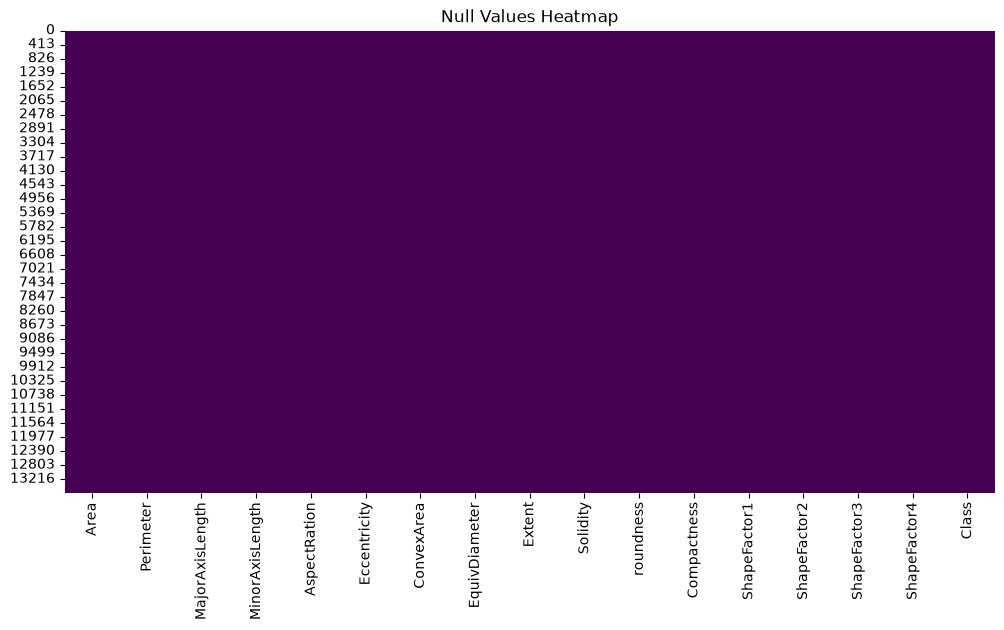

In [7]:
display(DF_DB.isnull().sum())
display(DF_DB.select_dtypes(include=['str']).apply(lambda x: x.unique()))

for col in DF_DB.select_dtypes(include=[np.number]).columns:
    Q1 = DF_DB[col].quantile(0.25)
    Q3 = DF_DB[col].quantile(0.75)
    IQR_Range = Q3 - Q1
    display('Outliers for Column ' + col, DF_DB.loc[((DF_DB[col] < (Q1 - 1.5 * IQR_Range)) | (DF_DB[col] > (Q3 + 1.5 * IQR_Range)))])
    display('Extreme Outliers for Column ' + col , DF_DB.loc[((DF_DB[col] < (Q1 - 1.72 * IQR_Range)) | (DF_DB[col] > (Q3 + 1.72 * IQR_Range)))])
    print()

plt.figure(figsize=(12, 6))
sns.heatmap(DF_DB.isnull(), cbar=False, cmap='viridis')
plt.title('Null Values Heatmap')
plt.show()

4. Feature Engineering & Preprocessing
-	Scale numerical features (StandardScaler / MinMaxScaler)
-	Encode categorical variables if necessary
-	Check and treat skewness if required
-	Split data into train/test sets (use stratified sampling while splitting)


### Feature Scaling (Standard Scaler), Encoding Y-Categorical and Splitting Data into Test and Train with Stratified Sampling

In [22]:
DF_DB_X = DF_DB.drop(columns=['Class'])
y_encoded = DF_DB['Class'].astype('category').cat.codes
X_train, X_test, y_train, y_test = train_test_split(
    DF_DB_X, y_encoded, test_size=0.15, random_state=42, stratify=y_encoded
)
skewness = DF_DB_X.skew().sort_values(ascending=False)
display(skewness)
cols = DF_DB_X.skew()[(DF_DB_X.skew() > 0.5) | (DF_DB_X.skew() < -0.5)].index
remaining_cols = [col for col in DF_DB_X.columns if col not in cols]
CT = ColumnTransformer([
    ("PT", PowerTransformer(method='yeo-johnson'), cols),
    ("ss", StandardScaler(), remaining_cols)
])
X_train_Transformed = CT.fit_transform(X_train)
X_test_Transformed = CT.transform(X_test)

Area               2.952931
ConvexArea         2.941821
MinorAxisLength    2.238211
EquivDiameter      1.948958
Perimeter          1.626124
MajorAxisLength    1.357815
AspectRation       0.582573
ShapeFactor2       0.301226
ShapeFactor3       0.242481
Compactness        0.037115
ShapeFactor1      -0.534141
roundness         -0.635749
Extent            -0.895348
Eccentricity      -1.062824
Solidity          -2.550093
ShapeFactor4      -2.759483
dtype: float64

5. Model Building: Try Multiple Classifiers, Train and test the dataset on a variety of supervised classification algorithms:
-	Logistic Regression
-	Decision Tree Classifier
-	Random Forest Classifier
-	K-Nearest Neighbors (KNN)
-	Support Vector Machine (SVM)
-	Ensemble Learning Methods
-	Naive Bayes and more…

Use Cross validation techniques to check if model performance is improved.


### Training and Testing Multiple Models on Base Parameters Prefered for the Dataset

{0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


'Confusion Matrix for Logistic Regression'

array([[178,   0,  15,   0,   0,   1,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  5,   0, 234,   0,   3,   2,   1],
       [  0,   0,   0, 477,   0,   9,  46],
       [  1,   0,   3,   4, 278,   0,   3],
       [  2,   0,   0,   3,   0, 293,   6],
       [  1,   0,   2,  30,   9,  10, 344]])

'Classification Report for Logistic Regression'

              precision    recall  f1-score   support

           0       0.95      0.90      0.92       198
           1       1.00      1.00      1.00        78
           2       0.92      0.96      0.94       245
           3       0.93      0.90      0.91       532
           4       0.96      0.96      0.96       289
           5       0.93      0.96      0.95       304
           6       0.85      0.87      0.86       396

    accuracy                           0.92      2042
   macro avg       0.93      0.94      0.93      2042
weighted avg       0.92      0.92      0.92      2042



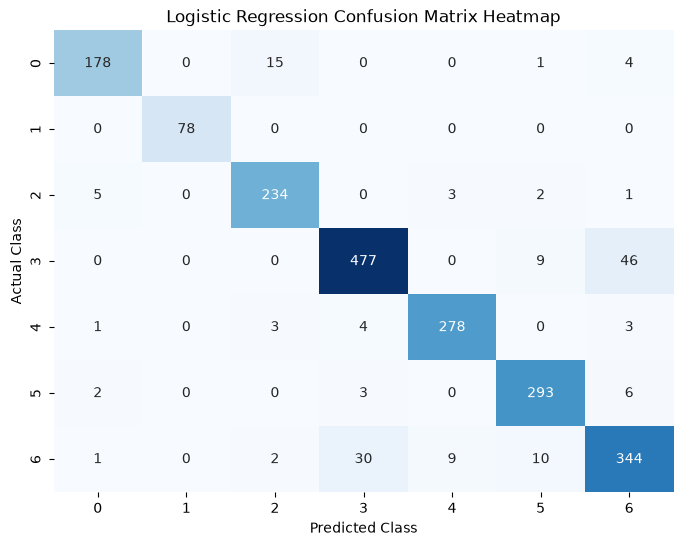

'Confusion Matrix for Decision Tree'

array([[171,   0,  17,   0,   1,   1,   8],
       [  0,  78,   0,   0,   0,   0,   0],
       [ 12,   0, 223,   0,   6,   1,   3],
       [  0,   0,   0, 469,   0,   8,  55],
       [  2,   0,   5,   4, 272,   0,   6],
       [  1,   0,   0,   4,   0, 292,   7],
       [  2,   0,   2,  30,  15,   8, 339]])

'Classification Report for Decision Tree'

              precision    recall  f1-score   support

           0       0.91      0.86      0.89       198
           1       1.00      1.00      1.00        78
           2       0.90      0.91      0.91       245
           3       0.93      0.88      0.90       532
           4       0.93      0.94      0.93       289
           5       0.94      0.96      0.95       304
           6       0.81      0.86      0.83       396

    accuracy                           0.90      2042
   macro avg       0.92      0.92      0.92      2042
weighted avg       0.90      0.90      0.90      2042



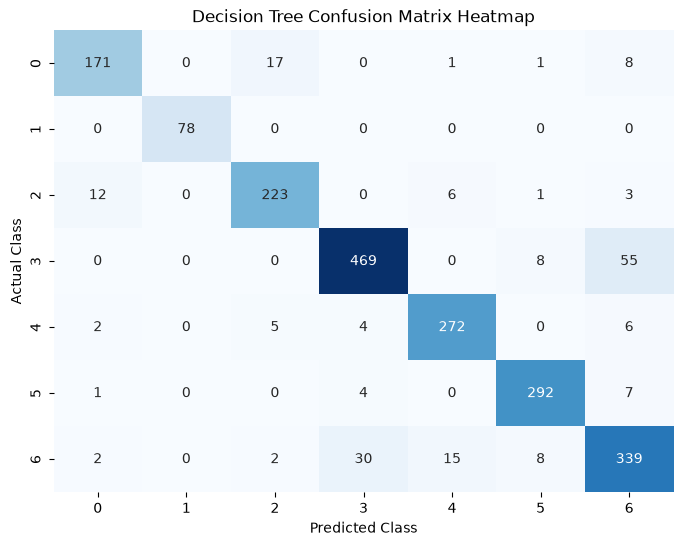

'Confusion Matrix for Random Forest'

array([[180,   0,  11,   0,   1,   0,   6],
       [  0,  78,   0,   0,   0,   0,   0],
       [  6,   0, 231,   0,   3,   2,   3],
       [  0,   0,   0, 478,   0,   9,  45],
       [  3,   0,   2,   4, 277,   0,   3],
       [  0,   0,   0,   4,   0, 293,   7],
       [  3,   0,   1,  32,   7,   6, 347]])

'Classification Report for Random Forest'

              precision    recall  f1-score   support

           0       0.94      0.91      0.92       198
           1       1.00      1.00      1.00        78
           2       0.94      0.94      0.94       245
           3       0.92      0.90      0.91       532
           4       0.96      0.96      0.96       289
           5       0.95      0.96      0.95       304
           6       0.84      0.88      0.86       396

    accuracy                           0.92      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.92      0.92      0.92      2042



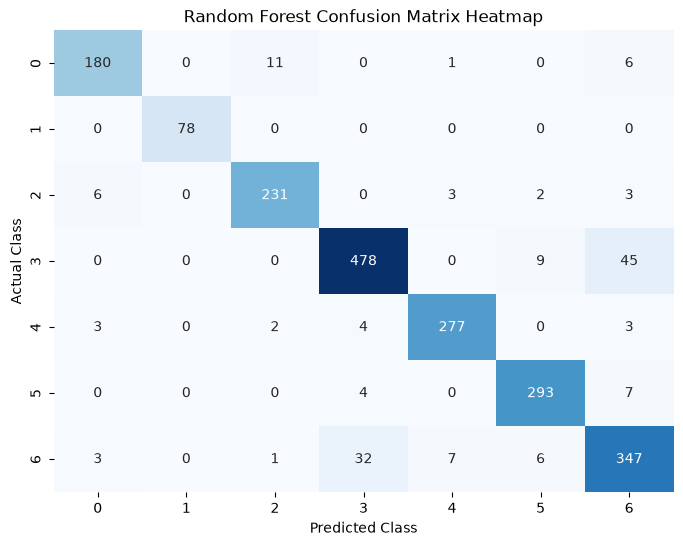

'Confusion Matrix for Gradient Boosting'

array([[177,   0,  13,   1,   1,   1,   5],
       [  0,  78,   0,   0,   0,   0,   0],
       [  4,   0, 233,   0,   4,   2,   2],
       [  0,   0,   0, 489,   1,   7,  35],
       [  3,   0,   2,   4, 276,   0,   4],
       [  0,   0,   0,   4,   0, 291,   9],
       [  1,   0,   1,  44,   8,   6, 336]])

'Classification Report for Gradient Boosting'

              precision    recall  f1-score   support

           0       0.96      0.89      0.92       198
           1       1.00      1.00      1.00        78
           2       0.94      0.95      0.94       245
           3       0.90      0.92      0.91       532
           4       0.95      0.96      0.95       289
           5       0.95      0.96      0.95       304
           6       0.86      0.85      0.85       396

    accuracy                           0.92      2042
   macro avg       0.94      0.93      0.93      2042
weighted avg       0.92      0.92      0.92      2042



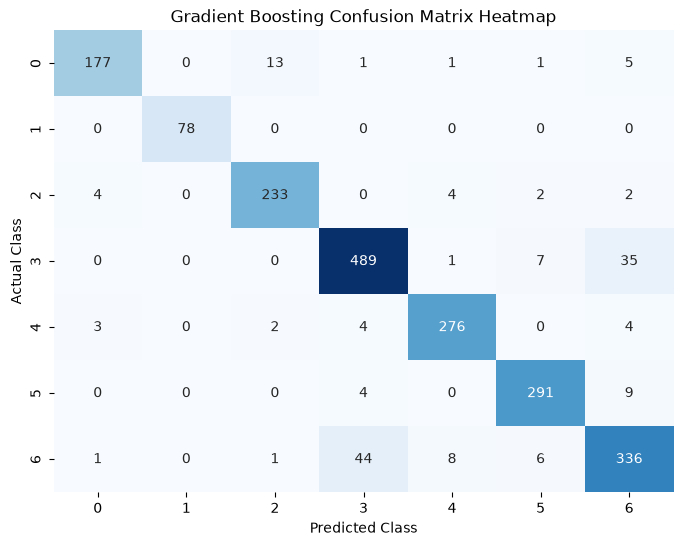

'Confusion Matrix for SVC'

array([[178,   0,  14,   0,   1,   1,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  5,   0, 234,   0,   3,   2,   1],
       [  0,   0,   0, 486,   0,   9,  37],
       [  1,   0,   3,   4, 279,   0,   2],
       [  0,   0,   0,   4,   0, 293,   7],
       [  2,   0,   0,  36,   6,   6, 346]])

'Classification Report for SVC'

              precision    recall  f1-score   support

           0       0.96      0.90      0.93       198
           1       1.00      1.00      1.00        78
           2       0.93      0.96      0.94       245
           3       0.92      0.91      0.92       532
           4       0.97      0.97      0.97       289
           5       0.94      0.96      0.95       304
           6       0.87      0.87      0.87       396

    accuracy                           0.93      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.93      0.93      0.93      2042



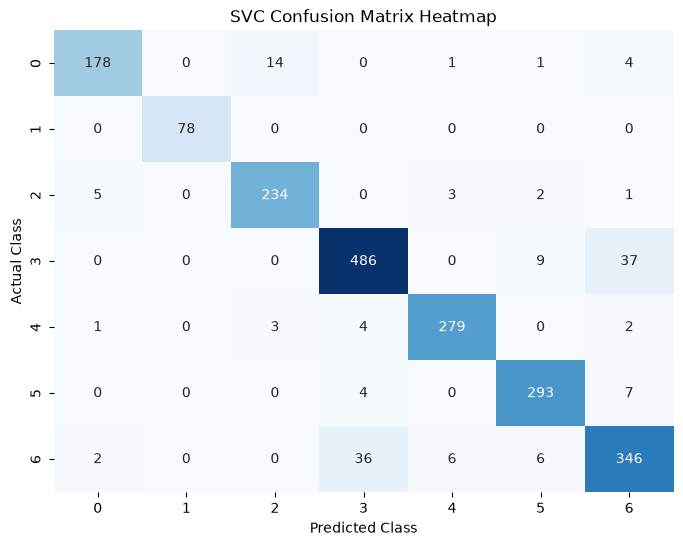

'Confusion Matrix for KNN'

array([[175,   0,  16,   0,   1,   1,   5],
       [  0,  78,   0,   0,   0,   0,   0],
       [  7,   0, 232,   0,   2,   2,   2],
       [  0,   0,   0, 486,   0,   6,  40],
       [  0,   0,   4,   4, 274,   0,   7],
       [  1,   0,   0,   5,   0, 290,   8],
       [  2,   0,   0,  42,   6,   3, 343]])

'Classification Report for KNN'

              precision    recall  f1-score   support

           0       0.95      0.88      0.91       198
           1       1.00      1.00      1.00        78
           2       0.92      0.95      0.93       245
           3       0.91      0.91      0.91       532
           4       0.97      0.95      0.96       289
           5       0.96      0.95      0.96       304
           6       0.85      0.87      0.86       396

    accuracy                           0.92      2042
   macro avg       0.94      0.93      0.93      2042
weighted avg       0.92      0.92      0.92      2042



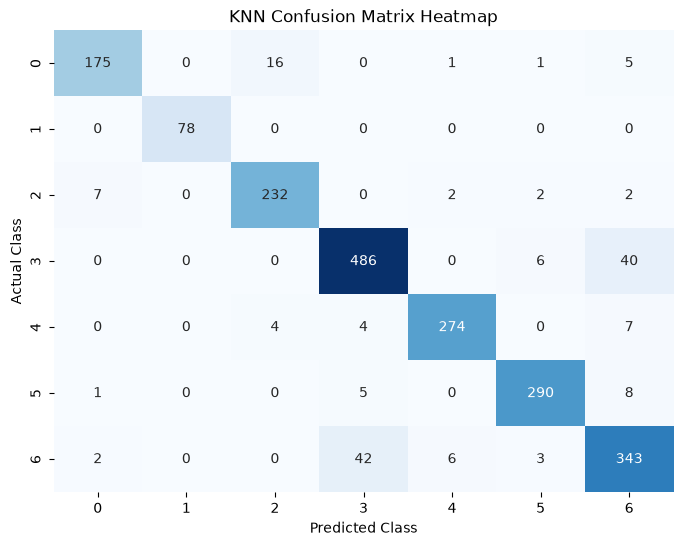

'Confusion Matrix for XG'

array([[182,   0,  10,   1,   1,   0,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  6,   0, 232,   0,   4,   2,   1],
       [  0,   0,   0, 485,   1,   5,  41],
       [  2,   0,   3,   4, 277,   0,   3],
       [  0,   0,   0,   4,   0, 291,   9],
       [  3,   0,   0,  42,   6,   7, 338]])

'Classification Report for XG'

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       198
           1       1.00      1.00      1.00        78
           2       0.95      0.95      0.95       245
           3       0.90      0.91      0.91       532
           4       0.96      0.96      0.96       289
           5       0.95      0.96      0.96       304
           6       0.85      0.85      0.85       396

    accuracy                           0.92      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.92      0.92      0.92      2042



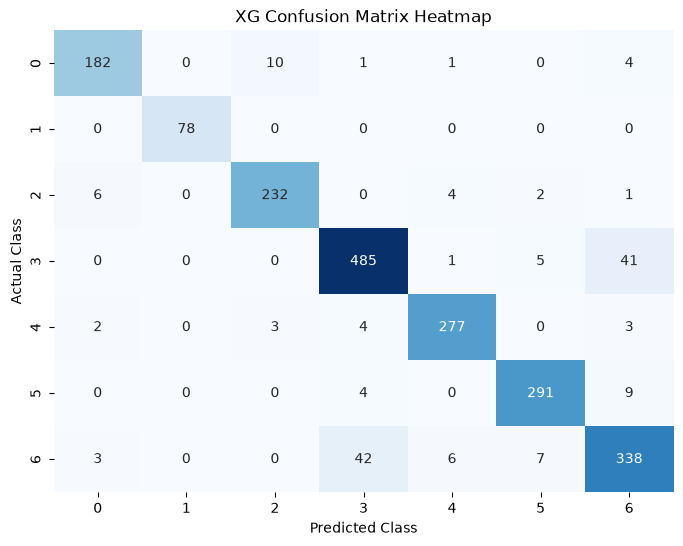

,Model,CV Accuracy,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,Overfitting (Y/N)
0,SVC,0.931,0.934,0.928,0.928,0.928,0.927,No
1,Random Forest,0.922,0.953,0.923,0.923,0.923,0.923,No
2,XG,0.928,0.999,0.922,0.922,0.922,0.922,Yes
3,Logistic Regression,0.926,0.928,0.922,0.922,0.922,0.922,No
4,Gradient Boosting,0.927,0.961,0.921,0.921,0.921,0.921,No
5,KNN,0.923,0.937,0.920,0.920,0.920,0.920,No
6,Decision Tree,0.904,0.950,0.903,0.904,0.903,0.903,No


In [23]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=2, min_samples_split=2, random_state=42, class_weight='balanced'
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=2, min_samples_split=5,
        max_features=0.8, random_state=42, n_jobs=-1, class_weight='balanced'
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVC": SVC(),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "XG" : XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.1, random_state=42, n_jobs=-1, subsample=0.8, colsample_bytree=0.8)
}

results = []
fitted_models = {}

category_mapping = dict(enumerate(DF_DB['Class'].astype('category').cat.categories))
print(category_mapping)

for name, estimator in models.items():
    estimator.fit(X_train_Transformed,y_train)

    cv_acc = cross_val_score(
        estimator, X_train_Transformed, y_train,
        cv=3, scoring="accuracy", n_jobs=-1
    ).mean()

    train_pred = estimator.predict(X_train_Transformed)
    test_pred = estimator.predict(X_test_Transformed)
    display('Confusion Matrix for ' + name, confusion_matrix(y_test, test_pred))
    display('Classification Report for ' + name)
    print(classification_report(y_test, test_pred))

    cm = confusion_matrix(y_test, test_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)

    plt.title(name + ' Confusion Matrix Heatmap')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.show()

    results.append({
        "Model": name,
        "CV Accuracy": cv_acc,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, average='weighted'),
        "Recall": recall_score(y_test, test_pred, average='weighted'),
        "F1 Score": f1_score(y_test, test_pred, average='weighted'),
        "Overfitting (Y/N)": "Yes" if accuracy_score(y_train, train_pred) > 0.98 and (accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred)) > 0.05 else "No"
    })

results_df = pd.DataFrame(results).sort_values(["F1 Score", "CV Accuracy"], ascending=False).reset_index(drop=True)
display(results_df.round(3))

6. Handling Class Imbalance, Apply techniques like:
 -	SMOTE (Synthetic Minority Over-sampling)
 -	Random Oversampling / Undersampling
 -	Class weighting

Evaluate if performance improves on minority classes

{0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


'Confusion Matrix for Logistic Regression'

array([[179,   0,  14,   0,   0,   1,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  5,   0, 235,   0,   3,   2,   0],
       [  0,   0,   0, 464,   0,  10,  58],
       [  2,   0,   3,   4, 277,   0,   3],
       [  2,   0,   0,   2,   0, 294,   6],
       [  1,   0,   2,  20,  10,  12, 351]])

'Classification Report for Logistic Regression'

              precision    recall  f1-score   support

           0       0.95      0.90      0.93       198
           1       1.00      1.00      1.00        78
           2       0.93      0.96      0.94       245
           3       0.95      0.87      0.91       532
           4       0.96      0.96      0.96       289
           5       0.92      0.97      0.94       304
           6       0.83      0.89      0.86       396

    accuracy                           0.92      2042
   macro avg       0.93      0.94      0.93      2042
weighted avg       0.92      0.92      0.92      2042



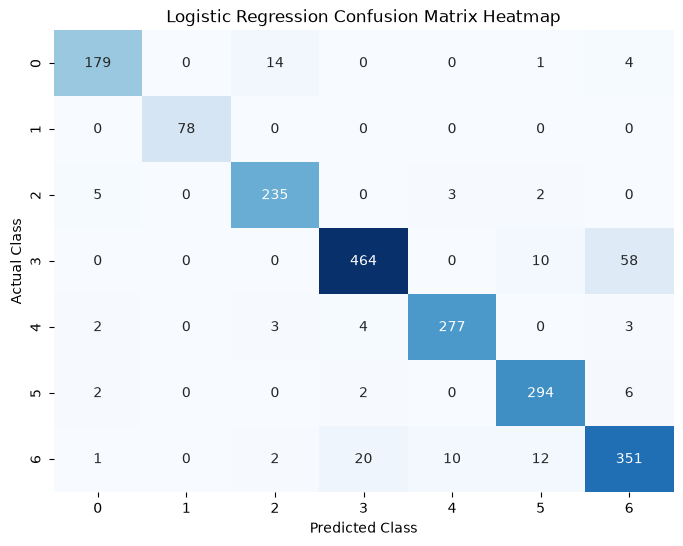

/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


'Confusion Matrix for Decision Tree'

array([[179,   0,  13,   0,   1,   1,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [ 16,   0, 223,   0,   3,   1,   2],
       [  0,   0,   0, 472,   0,  11,  49],
       [  7,   0,   4,   4, 268,   0,   6],
       [  0,   0,   0,   4,   0, 292,   8],
       [  5,   0,   3,  32,  11,   8, 337]])

'Classification Report for Decision Tree'

              precision    recall  f1-score   support

           0       0.86      0.90      0.88       198
           1       1.00      1.00      1.00        78
           2       0.92      0.91      0.91       245
           3       0.92      0.89      0.90       532
           4       0.95      0.93      0.94       289
           5       0.93      0.96      0.95       304
           6       0.83      0.85      0.84       396

    accuracy                           0.91      2042
   macro avg       0.92      0.92      0.92      2042
weighted avg       0.91      0.91      0.91      2042



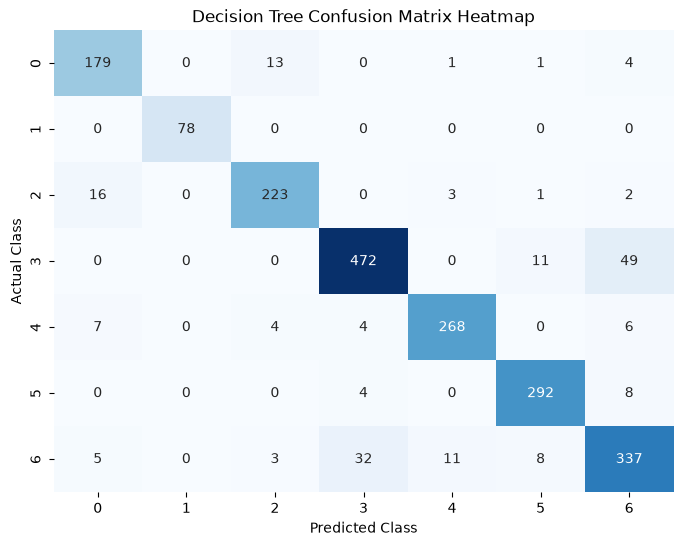

/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


'Confusion Matrix for Random Forest'

array([[180,   0,  11,   0,   1,   0,   6],
       [  0,  78,   0,   0,   0,   0,   0],
       [  7,   0, 229,   0,   4,   2,   3],
       [  0,   0,   0, 475,   0,   8,  49],
       [  3,   0,   3,   4, 277,   0,   2],
       [  0,   0,   0,   4,   0, 291,   9],
       [  3,   0,   2,  33,   7,   6, 345]])

'Classification Report for Random Forest'

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       198
           1       1.00      1.00      1.00        78
           2       0.93      0.93      0.93       245
           3       0.92      0.89      0.91       532
           4       0.96      0.96      0.96       289
           5       0.95      0.96      0.95       304
           6       0.83      0.87      0.85       396

    accuracy                           0.92      2042
   macro avg       0.93      0.93      0.93      2042
weighted avg       0.92      0.92      0.92      2042



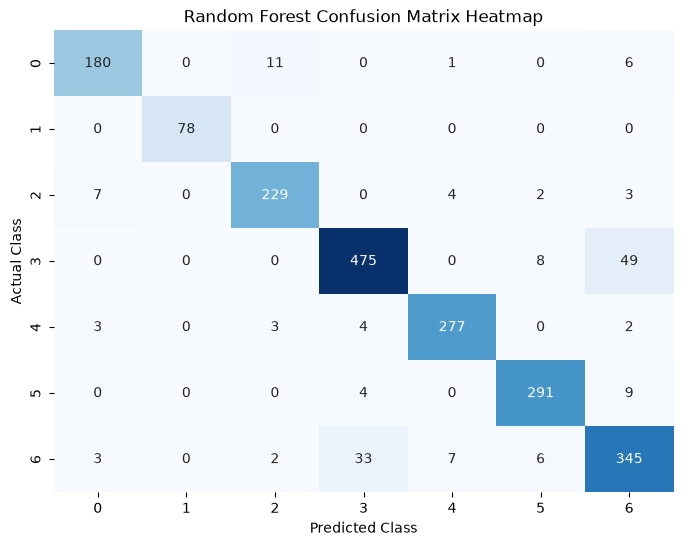

/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but GradientBoostingClassifier was fitted with feature names
  warnings.warn(


'Confusion Matrix for Gradient Boosting'

array([[180,   0,  13,   1,   1,   1,   2],
       [  0,  78,   0,   0,   0,   0,   0],
       [  5,   0, 232,   0,   4,   2,   2],
       [  0,   0,   0, 482,   1,   9,  40],
       [  1,   0,   2,   4, 277,   0,   5],
       [  1,   0,   0,   4,   0, 293,   6],
       [  3,   0,   1,  32,   8,   7, 345]])

'Classification Report for Gradient Boosting'

              precision    recall  f1-score   support

           0       0.95      0.91      0.93       198
           1       1.00      1.00      1.00        78
           2       0.94      0.95      0.94       245
           3       0.92      0.91      0.91       532
           4       0.95      0.96      0.96       289
           5       0.94      0.96      0.95       304
           6       0.86      0.87      0.87       396

    accuracy                           0.92      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.92      0.92      0.92      2042



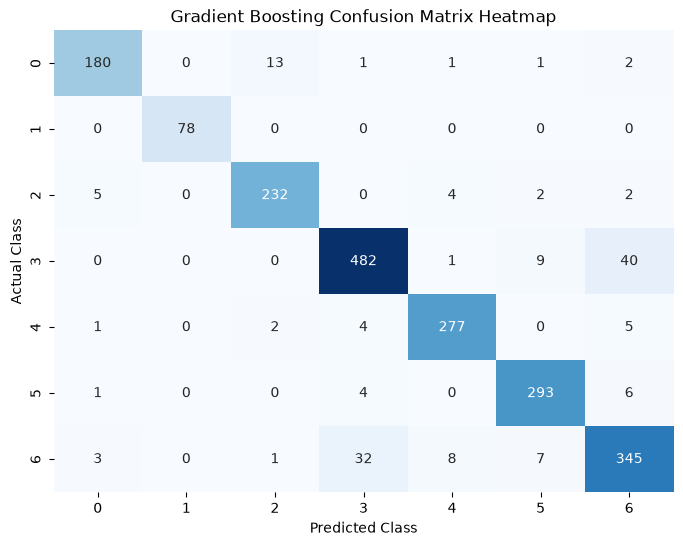

/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


'Confusion Matrix for SVC'

array([[181,   0,  12,   0,   0,   1,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  6,   0, 232,   0,   4,   2,   1],
       [  0,   0,   0, 475,   0,  10,  47],
       [  2,   0,   3,   4, 278,   0,   2],
       [  1,   0,   0,   2,   0, 296,   5],
       [  3,   0,   2,  27,   7,   7, 350]])

'Classification Report for SVC'

              precision    recall  f1-score   support

           0       0.94      0.91      0.93       198
           1       1.00      1.00      1.00        78
           2       0.93      0.95      0.94       245
           3       0.94      0.89      0.91       532
           4       0.96      0.96      0.96       289
           5       0.94      0.97      0.95       304
           6       0.86      0.88      0.87       396

    accuracy                           0.93      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.93      0.93      0.93      2042



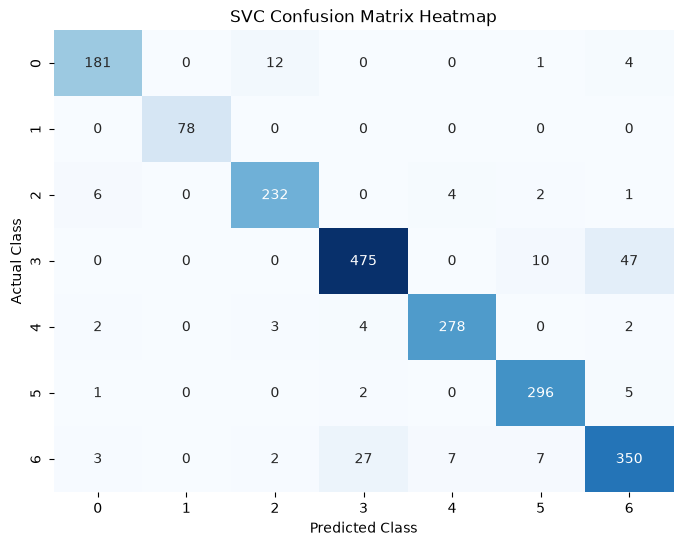

/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


'Confusion Matrix for KNN'

array([[178,   0,  13,   0,   1,   0,   6],
       [  0,  78,   0,   0,   0,   0,   0],
       [  6,   0, 233,   0,   3,   2,   1],
       [  0,   0,   0, 471,   0,  11,  50],
       [  1,   0,   7,   4, 272,   0,   5],
       [  3,   0,   1,   3,   0, 289,   8],
       [  5,   0,   2,  35,   7,   5, 342]])

'Classification Report for KNN'

              precision    recall  f1-score   support

           0       0.92      0.90      0.91       198
           1       1.00      1.00      1.00        78
           2       0.91      0.95      0.93       245
           3       0.92      0.89      0.90       532
           4       0.96      0.94      0.95       289
           5       0.94      0.95      0.95       304
           6       0.83      0.86      0.85       396

    accuracy                           0.91      2042
   macro avg       0.93      0.93      0.93      2042
weighted avg       0.91      0.91      0.91      2042



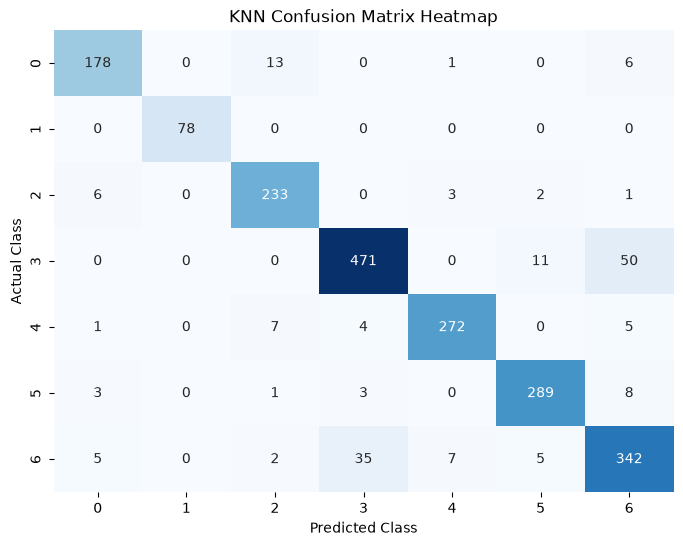

'Confusion Matrix for XG'

array([[180,   0,  12,   1,   1,   0,   4],
       [  0,  78,   0,   0,   0,   0,   0],
       [  6,   0, 232,   0,   4,   2,   1],
       [  0,   0,   0, 482,   1,   7,  42],
       [  2,   0,   3,   4, 277,   0,   3],
       [  1,   0,   0,   3,   0, 291,   9],
       [  4,   0,   1,  33,   6,   9, 343]])

'Classification Report for XG'

              precision    recall  f1-score   support

           0       0.93      0.91      0.92       198
           1       1.00      1.00      1.00        78
           2       0.94      0.95      0.94       245
           3       0.92      0.91      0.91       532
           4       0.96      0.96      0.96       289
           5       0.94      0.96      0.95       304
           6       0.85      0.87      0.86       396

    accuracy                           0.92      2042
   macro avg       0.93      0.93      0.93      2042
weighted avg       0.92      0.92      0.92      2042



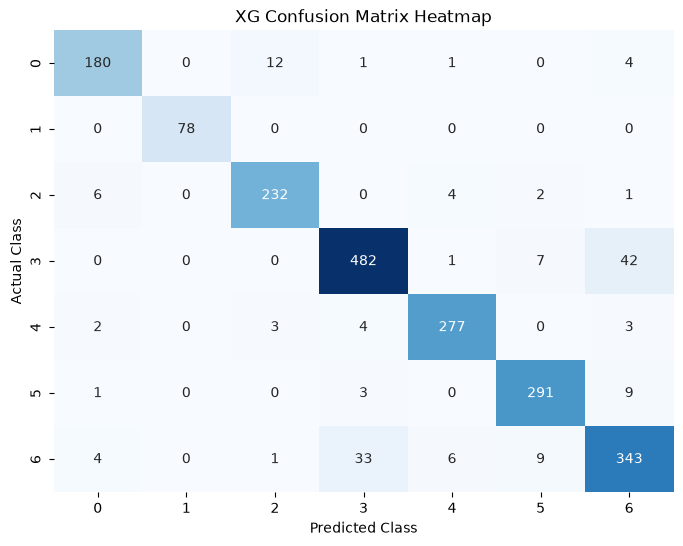

,Model,CV Accuracy,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,Overfitting (Y/N)
0,XG,0.960,0.999,0.922,0.922,0.922,0.922,Yes
1,KNN,0.950,0.964,0.912,0.913,0.912,0.913,No
2,Gradient Boosting,0.949,0.970,0.924,0.924,0.924,0.924,No
3,SVC,0.948,0.950,0.926,0.926,0.926,0.926,No
4,Random Forest,0.947,0.968,0.918,0.919,0.918,0.918,No
5,Logistic Regression,0.942,0.942,0.920,0.921,0.920,0.920,No
6,Decision Tree,0.937,0.962,0.905,0.906,0.905,0.906,No


In [ ]:
smote = SMOTE(random_state=42)
resampled_data = smote.fit_resample(X_train_Transformed, y_train)

X_train_smote, y_train_smote = resampled_data[0], resampled_data[1]

DF_X_train_smote = pd.DataFrame(X_train_smote, columns=DF_DB_X.columns)
DF_Y_train_smote = pd.Series(list(y_train_smote), name='Class')


models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=2, min_samples_split=2, random_state=42, class_weight='balanced'
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=2, min_samples_split=5,
        max_features=0.8, random_state=42, n_jobs=-1, class_weight='balanced'
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVC": SVC(),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "XG" : XGBClassifier(n_estimators=100, max_depth=10, learning_rate=0.1, random_state=42, n_jobs=-1, subsample=0.8, colsample_bytree=0.8)
}

results = []
fitted_models = {}

category_mapping = dict(enumerate(DF_DB['Class'].astype('category').cat.categories))
print(category_mapping)

for name, estimator in models.items():
    estimator.fit(DF_X_train_smote, DF_Y_train_smote)

    cv_acc = cross_val_score(
        estimator, DF_X_train_smote, DF_Y_train_smote,
        cv=3, scoring="accuracy", n_jobs=-1
    ).mean()

    train_pred = estimator.predict(DF_X_train_smote)
    test_pred = estimator.predict(X_test_Transformed)
    display('Confusion Matrix for ' + name, confusion_matrix(y_test, test_pred))
    display('Classification Report for ' + name)
    print(classification_report(y_test, test_pred))

    cm = confusion_matrix(y_test, test_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)

    plt.title(name + ' Confusion Matrix Heatmap')
    plt.xlabel('Predicted Class')
    plt.ylabel('Actual Class')
    plt.show()

    results.append({
        "Model": name,
        "CV Accuracy": cv_acc,
        "Train Accuracy": accuracy_score(DF_Y_train_smote, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred, average='weighted'),
        "Recall": recall_score(y_test, test_pred, average='weighted'),
        "F1 Score": f1_score(y_test, test_pred, average='weighted'),
        "Overfitting (Y/N)": "Yes" if accuracy_score(DF_Y_train_smote, train_pred) > 0.98 and (accuracy_score(DF_Y_train_smote, train_pred) - accuracy_score(y_test, test_pred)) > 0.05 else "No"
    })

results_df = pd.DataFrame(results).sort_values(["F1 Score", "CV Accuracy"], ascending=False).reset_index(drop=True)
display(results_df.round(3))

### Hyperparameter Tuning on Default Data

### Hyperparameter tuning for Random Forest Classifier using GridSearchCV

In [ ]:
param_grid = {
    'n_estimators': [100, 125],
    'max_depth': [6, 7, 8, 9, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 1.0]
}

rf_base = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train_Transformed, y_train)

best_rf_grid = grid_search.best_estimator_
print("\n--- Best Hyperparameters Found ---")
print(grid_search.best_params_)

train_pred = best_rf_grid.predict(X_train_Transformed)
test_pred = best_rf_grid.predict(X_test_Transformed)

print("\n--- Tuned Random Forest Model Performance ---")
print(f"Train Accuracy: {accuracy_score(y_train, train_pred):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision:      {precision_score(y_test, test_pred, average='weighted'):.4f}")
print(f"Recall:         {recall_score(y_test, test_pred, average='weighted'):.4f}")
print(f"F1 Score:       {f1_score(y_test, test_pred, average='weighted'):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_pred))
print(f"Overfitting:    {'Yes' if accuracy_score(y_train, train_pred) > 0.98 and (accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred)) > 0.05 else 'No'}")

### Hyperparameter tuning for SVC using GridSearchCV

In [ ]:
param_grid = [
    { 'kernel': ['linear'], 'C': [0.1, 1, 10, 100], 'decision_function_shape': ['ovr']},
    { 'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1], 'decision_function_shape': ['ovr', 'ovo']},
    { 'kernel': ['poly'], 'C': [0.1, 1, 10], 'degree': [2, 3, 4], 'gamma': ['scale', 'auto', 0.1], 'decision_function_shape': ['ovr', 'ovo'] }
]

svc = SVC(random_state=42)

grid_search = GridSearchCV(
    estimator=svc,
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_Transformed, y_train)

best_svc_grid = grid_search.best_estimator_
print("\n--- Best Hyperparameters Found ---")
print(grid_search.best_params_)

train_pred = best_svc_grid.predict(X_train_Transformed)
test_pred = best_svc_grid.predict(X_test_Transformed)

print("\n--- Tuned SVC Model Performance ---")
print(f"Train Accuracy: {accuracy_score(y_train, train_pred):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision:      {precision_score(y_test, test_pred, average='weighted'):.4f}")
print(f"Recall:         {recall_score(y_test, test_pred, average='weighted'):.4f}")
print(f"F1 Score:       {f1_score(y_test, test_pred, average='weighted'):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_pred))
print(f"Overfitting:    {'Yes' if accuracy_score(y_train, train_pred) > 0.98 and (accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred)) > 0.05 else 'No'}")

Fitting 5 folds for each of 106 candidates, totalling 530 fits

--- Best Hyperparameters Found ---
{'C': 100, 'decision_function_shape': 'ovr', 'gamma': 0.01, 'kernel': 'rbf'}

--- Tuned Model Performance ---
Train Accuracy: 0.9377
Test Accuracy:  0.9275
Precision:      0.9274
Recall:         0.9275
F1 Score:       0.9274

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.93       198
           1       1.00      1.00      1.00        78
           2       0.94      0.94      0.94       245
           3       0.91      0.92      0.92       532
           4       0.97      0.96      0.96       289
           5       0.95      0.97      0.96       304
           6       0.87      0.86      0.87       396

    accuracy                           0.93      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.93      0.93      0.93      2042

Overfitting:    No


### Hyperparameter tuning for Logistic Regression using GridSearchCV

In [29]:
param_grid_lr = [
    {
        'solver': ['lbfgs'],
        'C': [0.01, 0.1, 1, 10, 100],
        'max_iter': [4000]
    },
    {
        'solver': ['saga'],
        'l1_ratio': [0.0, 0.5, 1.0],
        'C': [0.01, 0.1, 1, 10, 100],
        'max_iter': [4000]
    }
]

lr = LogisticRegression(random_state=42)

grid_search_lr = GridSearchCV(
    estimator=lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search_lr.fit(X_train_Transformed, y_train)

best_lr_grid = grid_search_lr.best_estimator_
print("\n--- Best Hyperparameters Found (Logistic Regression) ---")
print(grid_search_lr.best_params_)

train_pred = best_lr_grid.predict(X_train_Transformed)
test_pred = best_lr_grid.predict(X_test_Transformed)

print("\n--- Tuned Logistic Regression Model Performance ---")
print(f"Train Accuracy: {accuracy_score(y_train, train_pred):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, test_pred):.4f}")
print(f"Precision:      {precision_score(y_test, test_pred, average='weighted'):.4f}")
print(f"Recall:         {recall_score(y_test, test_pred, average='weighted'):.4f}")
print(f"F1 Score:       {f1_score(y_test, test_pred, average='weighted'):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_pred))
print(f"Overfitting:    {'Yes' if accuracy_score(y_train, train_pred) > 0.98 and (accuracy_score(y_train, train_pred) - accuracy_score(y_test, test_pred)) > 0.05 else 'No'}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits


/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(



--- Best Hyperparameters Found (Logistic Regression) ---
{'C': 100, 'l1_ratio': 1.0, 'max_iter': 4000, 'solver': 'saga'}

--- Tuned Logistic Regression Model Performance ---
Train Accuracy: 0.9308
Test Accuracy:  0.9290
Precision:      0.9301
Recall:         0.9290
F1 Score:       0.9291

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.89      0.93       198
           1       1.00      1.00      1.00        78
           2       0.92      0.96      0.94       245
           3       0.94      0.90      0.92       532
           4       0.97      0.96      0.96       289
           5       0.94      0.97      0.95       304
           6       0.86      0.90      0.88       396

    accuracy                           0.93      2042
   macro avg       0.94      0.94      0.94      2042
weighted avg       0.93      0.93      0.93      2042

Overfitting:    No


/Users/manav_21/E&ICT_Practice/venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


#### Here after Hyperparameter Tunning Logistic Regression is Best Model for Predicting in Training as well as Testing without Overfitting issue

### Exporting Model (SVC)

In [31]:
categories = DF_DB['Class'].astype('category').cat.categories
label_mapping = dict(enumerate(categories))
model_dict = {
    "CT": CT,
    "model": best_lr_grid,
    "mapping" : label_mapping
}
with open("Dry_Beans_Model.pkl", "wb") as file:
    pickle.dump(model_dict, file)